# Which House Sold It?

### A logistic classifier for Bonhams vs. Phillips, fit by Newton's method

The hedonic model asks *what explains the price of an artwork*. This notebook turns that
question around: **given an artwork's characteristics, can we tell which auction house sold it?**

If the answer is yes, the two houses sell systematically different art — and the "house premium"
in a hedonic regression is partly measuring *what* is sold, not just *where*.

Logistic regression has no closed-form solution, so we fit it with **Newton's method**, written
from scratch in NumPy and verified against scikit-learn.

---
**Data** · 30,241 sold lots, 2023–2026
**Training** · Nov 2023 – Dec 2025 (21,783 lots) &nbsp;·&nbsp; **Test** · Jan – Oct 2026 (8,458 lots)

## 0 · Setup

In [29]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ---- visual identity -------------------------------------------------------
INK      = '#2E3B47'   # Bonhams
CLAY     = '#C0703E'   # Phillips
RULE     = '#D9D4CB'
PAPER    = '#FBFAF7'
MUTED    = '#8A8378'

mpl.rcParams.update({
    'figure.facecolor'  : PAPER,
    'axes.facecolor'    : PAPER,
    'savefig.facecolor' : PAPER,
    'font.family'       : 'DejaVu Sans',
    'font.size'         : 10.5,
    'axes.edgecolor'    : RULE,
    'axes.linewidth'    : 1.0,
    'axes.labelcolor'   : '#4A4A4A',
    'axes.titlesize'    : 13,
    'axes.titleweight'  : 'normal',
    'axes.titlepad'     : 14,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'xtick.color'       : MUTED,
    'ytick.color'       : MUTED,
    'xtick.labelsize'   : 9.5,
    'ytick.labelsize'   : 9.5,
    'grid.color'        : RULE,
    'grid.linewidth'    : 0.8,
    'legend.frameon'    : False,
    'figure.dpi'        : 110,
})

def rule(title=''):
    print('\n' + title)
    print('─' * 62)

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 40)
print('ready')

ready


## 1 · Load the data


These are the project's standard train/test split with pre-sale estimates merged back in.

In [30]:
BASE = 'https://raw.githubusercontent.com/ajavakhishvili16/APMA-PROJECT/main/'

train = pd.read_csv(BASE + 'auction_train_with_estimates.csv', low_memory=False)
test  = pd.read_csv(BASE + 'auction_test_with_estimates.csv',  low_memory=False)

# target: 1 = Phillips, 0 = Bonhams
y_train = (train['source'] == 'phillips').astype(float).values
y_test  = (test['source']  == 'phillips').astype(float).values

rule('SPLIT')
for name, d, y in [('train', train, y_train), ('test', test, y_test)]:
    print(f'{name:<6} {len(d):>6,} lots   {d.auction_date.min()} to {d.auction_date.max()}'
          f'   Phillips {y.mean():.1%}')
print(f'\nBaseline accuracy if we always guess Bonhams: {1 - y_test.mean():.1%}')


SPLIT
──────────────────────────────────────────────────────────────
train  21,783 lots   2023-11-09 to 2025-12-18   Phillips 18.4%
test    8,458 lots   2026-01-22 to 2026-10-07   Phillips 21.5%

Baseline accuracy if we always guess Bonhams: 78.5%


## 2 · The leakage audit

Before modelling, we remove every column that identifies the house by something other than the
art itself. Scraped data is full of these: a model that learns *which scraper wrote the row*
scores beautifully and means nothing.

The ones we found in this dataset:

In [31]:
leaks = pd.DataFrame([
 ('source',            'is the target itself'),
 ('source_url',        'contains phillips.com / bonhams.com'),
 ('currency',          'AUD and EUR lots are 100% Bonhams'),
 ('price_realized',    'local-currency amount reconstructs currency'),
 ('fx_to_usd',         'reconstructs currency'),
 ('cpi_sale_month',    'deterministic function of the sale month'),
 ('inflation_factor',  'deterministic function of the sale month'),
 ('ln_ppa',            'exactly ln(price) - ln_area -> singular Hessian'),
 ('sitelinks',         'exactly exp(fame) - 1, and 40% missing'),
 ('cluster',           '8,372 artist levels; 34% of test artists unseen'),
 ('artist_name',       'free text'),
 ('artwork_title',     'free text; capitalisation differs by house'),
 ('medium',            'raw text, 12,591 levels; medium_c is the clean version'),
], columns=['column', 'why it is dropped'])

rule('DROPPED')
print(leaks.to_string(index=False))

# the two exact identities, verified rather than asserted
ident = np.log(train.price_usd_2026) - train.ln_area - train.ln_ppa
print(f'\nln(price) - ln_area - ln_ppa      sd = {ident.std():.2e}   (an exact identity)')
print(f'fame == log(1 + sitelinks)        {np.allclose(train.fame.where(train.sitelinks.notna()).dropna(), np.log1p(train.sitelinks.dropna()))}')


DROPPED
──────────────────────────────────────────────────────────────
          column                                      why it is dropped
          source                                   is the target itself
      source_url                    contains phillips.com / bonhams.com
        currency                      AUD and EUR lots are 100% Bonhams
  price_realized            local-currency amount reconstructs currency
       fx_to_usd                                  reconstructs currency
  cpi_sale_month               deterministic function of the sale month
inflation_factor               deterministic function of the sale month
          ln_ppa        exactly ln(price) - ln_area -> singular Hessian
       sitelinks                 exactly exp(fame) - 1, and 40% missing
         cluster        8,372 artist levels; 34% of test artists unseen
     artist_name                                              free text
   artwork_title             free text; capitalisation differs b

### What we keep

Only genuine artwork characteristics, in three nested blocks. The blocks matter: comparing
them is how we answer the house-premium question.

| block | features |
|---|---|
| **A · artwork** | size (`ln_area`, `ln_area²`), medium, support, period created, artist fame, market exposure, season |
| **B · + estimates** | pre-sale low estimate, estimate spread `log(high/low)` |
| **C · + price** | realized price (2026 dollars), surprise `log(price / estimate midpoint)` |

Two features carry a missingness flag rather than a silent imputation: `wiki_missing`
(no Wikipedia match for the artist) and `est_missing` (~1% of lots). Whether a record is
incomplete may itself differ by house, and we would rather measure that than hide it.

In [32]:
CATS = ['medium_c', 'support_c', 'created_period', 'exposure', 'season']

def build_features(df, estimates=True, price=True):
    X = pd.DataFrame(index=df.index)

    # --- the artwork ---
    X['ln_area']        = df['ln_area']
    X['ln_area_sq']     = df['ln_area2']
    X['fame']           = df['fame']
    X['wiki_missing']   = (df['fame'] == 0).astype(float)
    X['ln_prior_lots']  = np.log1p(df['n_prior_lots'].fillna(0))
    X['prior_missing']  = df['n_prior_lots'].isna().astype(float)
    X['n_markets']      = df['n_markets_to_date'].fillna(1)

    lo, hi = df['estimate_low_usd'], df['estimate_high_usd']
    mid = (lo + hi) / 2

    # --- what the house expected it to fetch ---
    if estimates:
        X['est_missing'] = lo.isna().astype(float)
        X['ln_est_low']  = np.log(lo.where(lo > 0)).fillna(0)
        X['est_spread']  = np.log((hi / lo).where((lo > 0) & (hi > 0))).fillna(0)

    # --- what it actually fetched ---
    if price:
        X['ln_price'] = np.log(df['price_usd_2026'])
        if estimates:
            X['surprise'] = np.log((df['price_usd_2026'] / mid).where(mid > 0)).fillna(0)

    for c in CATS:
        X = X.join(pd.get_dummies(df[c].astype(str), prefix=c, drop_first=True, dtype=float))
    return X


def design_matrices(tr_df, te_df):
    '''Align columns, standardise using TRAIN statistics only, prepend an intercept.'''
    cols = sorted(set(tr_df.columns) | set(te_df.columns))
    A = tr_df.reindex(columns=cols, fill_value=0.0).values.astype(float)
    B = te_df.reindex(columns=cols, fill_value=0.0).values.astype(float)
    mu, sd = A.mean(0), A.std(0)
    sd = np.where(sd < 1e-12, 1.0, sd)
    A, B = (A - mu) / sd, (B - mu) / sd
    ones = lambda M: np.hstack([np.ones((len(M), 1)), M])
    return ones(A), ones(B), ['intercept'] + cols


X_tr, X_te, COLS = design_matrices(build_features(train), build_features(test))
rule('DESIGN MATRIX')
print(f'{X_tr.shape[0]:,} x {X_tr.shape[1]} (train)    {X_te.shape[0]:,} x {X_te.shape[1]} (test)')
print(f'condition number: {np.linalg.cond(X_tr):,.1f}   (low is good - the Hessian will invert cleanly)')


DESIGN MATRIX
──────────────────────────────────────────────────────────────
21,783 x 34 (train)    8,458 x 34 (test)
condition number: 37.3   (low is good - the Hessian will invert cleanly)


## 3 · The model, and why it needs Newton's method

For lot $i$ with features $\mathbf{x}_i$, the probability it was sold by **Phillips**:

$$p_i \;=\; \sigma(\mathbf{x}_i^\top\boldsymbol\beta) \;=\; \frac{1}{1+e^{-\mathbf{x}_i^\top\boldsymbol\beta}}$$

We choose $\boldsymbol\beta$ to maximise the penalised log-likelihood

$$\ell(\boldsymbol\beta)=\sum_i\Big[y_i\log p_i+(1-y_i)\log(1-p_i)\Big]-\tfrac{\lambda}{2}\lVert\boldsymbol\beta_{-0}\rVert^2$$

### The contrast with the hedonic regression

| | hedonic OLS | this classifier |
|---|---|---|
| model | $\ln(\text{price}) = \mathbf{x}^\top\boldsymbol\beta + \varepsilon$ | $P(\text{Phillips}) = \sigma(\mathbf{x}^\top\boldsymbol\beta)$ |
| solution | **closed form**, $\hat{\boldsymbol\beta}=(X^\top X)^{-1}X^\top y$ | **none** — the sigmoid makes it nonlinear |
| computation | one solve | iterate until converged |

Newton's method uses the curvature as well as the slope:

$$\mathbf{g} = X^\top(\mathbf{y}-\mathbf{p}) \qquad
\mathbf{H} = X^\top W X + \lambda I, \quad W=\mathrm{diag}\big(p_i(1-p_i)\big)$$

$$\boxed{\;\boldsymbol\beta \leftarrow \boldsymbol\beta + \mathbf{H}^{-1}\mathbf{g}\;}$$

Each step is a **weighted least-squares problem** whose weights $p_i(1-p_i)$ change every
iteration — which is why the method is also called **IRLS**, *iteratively reweighted least
squares*. The classifier is, quite literally, a sequence of reweighted hedonic regressions
on the same design matrix.

> Newton's method does solve a linear system
> at every step. What logistic regression lacks is a *single closed-form* solution like the
> one OLS enjoys. And we never form $\mathbf{H}^{-1}$ explicitly — we solve $\mathbf{H}\Delta=\mathbf{g}$,
> which is faster and numerically far steadier.

### The implementation

In [33]:
def newton_logistic(X, y, lam=1.0, tol=1e-8, max_iter=50, verbose=True):
    """Fit logistic regression by Newton-Raphson (IRLS). Intercept is not penalised."""
    n, d = X.shape
    beta    = np.zeros(d)
    penalty = np.r_[0.0, np.ones(d - 1)]
    history = []

    if verbose:
        print(f"{'iter':>4} {'log-likelihood':>18} {'||step||':>12} {'max|beta|':>11}")
        print('─' * 49)

    for t in range(1, max_iter + 1):
        eta = np.clip(X @ beta, -30, 30)
        p   = 1.0 / (1.0 + np.exp(-eta))

        loglik = (np.sum(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
                  - 0.5 * lam * np.sum(penalty * beta ** 2))

        g = X.T @ (y - p) - lam * penalty * beta          # gradient
        w = np.clip(p * (1 - p), 1e-10, None)             # IRLS weights
        H = X.T @ (X * w[:, None]) + lam * np.diag(penalty)   # Hessian (+ ridge)

        step = np.linalg.solve(H, g)                      # solve, never invert
        beta = beta + step

        size = np.linalg.norm(step)
        history.append(dict(iteration=t, loglik=loglik, step=size,
                            max_abs_beta=np.abs(beta).max()))
        if verbose:
            print(f'{t:>4} {loglik:>18,.4f} {size:>12.3e} {np.abs(beta).max():>11.3f}')
        if size < tol:
            if verbose:
                print(f'\nconverged in {t} iterations')
            break

    return beta, pd.DataFrame(history)


def predict_proba(X, beta):
    return 1.0 / (1.0 + np.exp(-np.clip(X @ beta, -30, 30)))

### Run it

In [34]:
beta, history = newton_logistic(X_tr, y_train, lam=1.0)

iter     log-likelihood     ||step||   max|beta|
─────────────────────────────────────────────────
   1       -15,098.8250    2.160e+00       1.266
   2        -6,435.9874    1.243e+00       1.993
   3        -5,046.3865    1.179e+00       2.645
   4        -4,618.0640    1.241e+00       3.136
   5        -4,517.6830    5.917e-01       3.388
   6        -4,502.7731    2.381e-01       3.471
   7        -4,501.2524    1.185e-01       3.495
   8        -4,501.0598    7.769e-02       3.505
   9        -4,501.0254    2.993e-02       3.509
  10        -4,501.0227    3.289e-03       3.509
  11        -4,501.0226    3.431e-05       3.509
  12        -4,501.0226    3.669e-09       3.509

converged in 12 iterations


iter: the Newton step number.
log-likelihood: how well the model explains the training data. It is always negative, and closer to 0 is better.
‖step‖: how far β moved in this step. This is the size of H⁻¹g.
max|beta|: the largest coefficient in absolute size, in standardized units.
\
Note the shape of that convergence. The step size falls roughly **quadratically** near the
optimum — `1e-1 → 1e-3 → 1e-5 → 1e-9`. Each iteration roughly doubles the number of correct
digits. That is the signature of Newton's method, and it is why we needed twelve iterations
rather than thousands.

## 4 · Is the implementation correct?

The honest test: fit the same penalised objective with scikit-learn's own solver and compare
coefficients. With `C = 1/λ` the two objectives are identical, so the answer should match to
floating-point precision.

In [35]:
from sklearn.linear_model import LogisticRegression

sk = LogisticRegression(C=1.0, solver='newton-cg', max_iter=1000, tol=1e-10)
sk.fit(X_tr[:, 1:], y_train)                       # sklearn fits its own intercept
theirs = np.r_[sk.intercept_[0], sk.coef_[0]]

gap = np.abs(beta - theirs).max()
rule('VERIFICATION')
print(f'largest coefficient disagreement: {gap:.2e}')
print('identical to machine precision' if gap < 1e-6 else 'MISMATCH - investigate')

print()
print(pd.DataFrame({'ours': beta[:6], 'scikit-learn': theirs[:6]},
                   index=COLS[:6]).round(8).to_string())


VERIFICATION
──────────────────────────────────────────────────────────────
largest coefficient disagreement: 6.54e-11
identical to machine precision

                             ours  scikit-learn
intercept               -3.509346     -3.509346
created_period_1900_44   0.284636      0.284636
created_period_1945_69   0.848262      0.848262
created_period_1970_99   1.419447      1.419447
created_period_2000plus  2.227630      2.227630
created_period_pre1800  -0.467874     -0.467874


## 6 · Three nested models

This is the heart of it. Each model adds one block of information, and the gain in AUC
measures what that block tells us about the house.

- **A — artwork only.** Size, medium, support, period, artist fame, exposure.
- **B — plus pre-sale estimates.** What the house *expected* the work to fetch.
- **C — plus realized price.** What it *actually* fetched.

In [36]:
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, roc_curve

SPECS = [
    ('A  artwork only',     dict(estimates=False, price=False)),
    ('B  + estimates',      dict(estimates=True,  price=False)),
    ('C  + realized price', dict(estimates=True,  price=True)),
]

models = {}
for name, kw in SPECS:
    Xa, Xb, cols = design_matrices(build_features(train, **kw), build_features(test, **kw))
    b, h = newton_logistic(Xa, y_train, lam=1.0, verbose=False)
    p = predict_proba(Xb, b)
    models[name] = dict(beta=b, hist=h, cols=cols, p=p,
                        auc=roc_auc_score(y_test, p),
                        acc=accuracy_score(y_test, p >= 0.5),
                        k=Xa.shape[1])

summary = pd.DataFrame({
    'features'  : [models[n]['k'] for n, _ in SPECS],
    'iterations': [len(models[n]['hist']) for n, _ in SPECS],
    'test AUC'  : [models[n]['auc'] for n, _ in SPECS],
    'accuracy'  : [models[n]['acc'] for n, _ in SPECS],
}, index=[n for n, _ in SPECS])
summary['vs baseline'] = summary['accuracy'] - (1 - y_test.mean())

rule('OUT-OF-SAMPLE PERFORMANCE  (trained 2023-25, tested on 2026)')
print(summary.round(4).to_string())
print(f'\nalways-Bonhams baseline accuracy: {1 - y_test.mean():.4f}')


OUT-OF-SAMPLE PERFORMANCE  (trained 2023-25, tested on 2026)
──────────────────────────────────────────────────────────────
                     features  iterations  test AUC  accuracy  vs baseline
A  artwork only            29          12    0.8575    0.8496       0.0648
B  + estimates             32          12    0.8906    0.8703       0.0855
C  + realized price        34          12    0.8901    0.8697       0.0849

always-Bonhams baseline accuracy: 0.7848


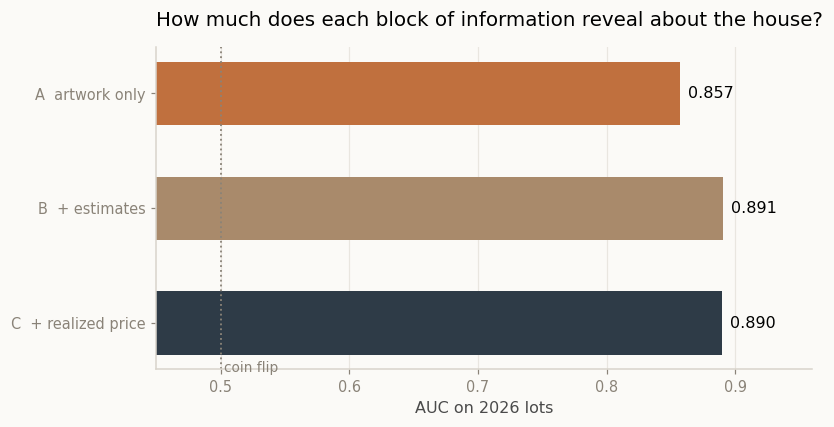

adding pre-sale estimates : +0.0331 AUC
adding realized price     : -0.0005 AUC


In [37]:
fig, ax = plt.subplots(figsize=(7.6, 4.0))
names = [n for n, _ in SPECS]
vals  = [models[n]['auc'] for n in names]
bars  = ax.barh(names[::-1], vals[::-1], color=[CLAY, '#A98A6B', INK][::-1], height=.55)
ax.axvline(0.5, color=MUTED, ls=':', lw=1.2)
ax.text(0.503, -0.42, 'coin flip', color=MUTED, fontsize=9)
for b_, v in zip(bars, vals[::-1]):
    ax.text(v + .006, b_.get_y() + b_.get_height()/2, f'{v:.3f}', va='center', fontsize=10.5)
ax.set_xlim(0.45, 0.96); ax.set_xlabel('AUC on 2026 lots')
ax.set_title('How much does each block of information reveal about the house?', loc='left')
ax.grid(axis='x', alpha=.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

gap_est   = models['B  + estimates']['auc'] - models['A  artwork only']['auc']
gap_price = models['C  + realized price']['auc'] - models['B  + estimates']['auc']
print(f'adding pre-sale estimates : {gap_est:+.4f} AUC')
print(f'adding realized price     : {gap_price:+.4f} AUC')

### Reading that result

The estimates block buys a real improvement. The realized price, added on top, buys almost
nothing.

That is the interesting finding, and it has a clean interpretation: **the pre-sale estimate
already contains everything the hammer price would tell us about which house is selling.**
The estimate is the house's own expert valuation, published before the sale; the price is
that valuation plus noise from the room. For the hedonic model this matters — it suggests the
house effect lives in *how a house values and selects work*, not in some separate premium the
auction itself confers.

## 7 · What actually distinguishes the two houses?

Coefficients are on standardised features, so they are directly comparable. Positive values
push a lot toward **Phillips**, negative toward **Bonhams**.

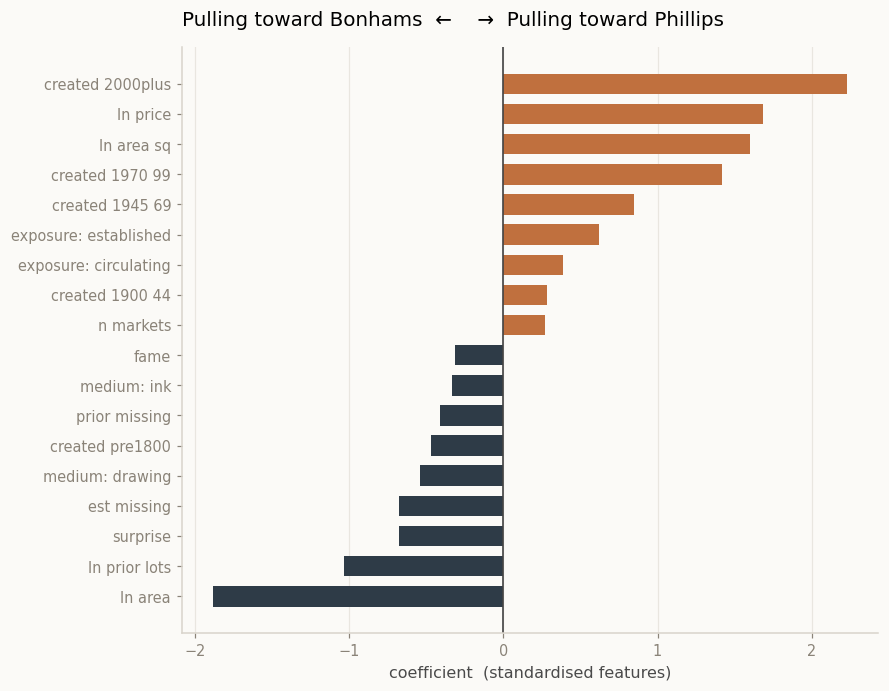


STRONGEST SIGNALS
──────────────────────────────────────────────────────────────
                         coefficient  odds ratio
ln_area                       -1.882       0.152
ln_prior_lots                 -1.033       0.356
surprise                      -0.678       0.507
est_missing                   -0.676       0.509
medium_c_drawing              -0.545       0.580
created_period_1945_69         0.848       2.336
created_period_1970_99         1.419       4.135
ln_area_sq                     1.598       4.943
ln_price                       1.683       5.379
created_period_2000plus        2.228       9.278


In [38]:
m = models['C  + realized price']
coef = pd.Series(m['beta'], index=m['cols']).drop('intercept').sort_values()
show = pd.concat([coef.head(9), coef.tail(9)])

fig, ax = plt.subplots(figsize=(8.2, 6.4))
colors = [INK if v < 0 else CLAY for v in show.values]
ax.barh(range(len(show)), show.values, color=colors, height=.68)
ax.set_yticks(range(len(show)))
ax.set_yticklabels([s.replace('created_period_', 'created ')
                     .replace('medium_c_', 'medium: ')
                     .replace('support_c_', 'support: ')
                     .replace('exposure_', 'exposure: ')
                     .replace('season_', 'sold in ')
                     .replace('_', ' ') for s in show.index])
ax.axvline(0, color='#444', lw=1.1)
ax.set_xlabel('coefficient  (standardised features)')
ax.set_title('Pulling toward Bonhams  ←    →  Pulling toward Phillips', loc='left')
ax.grid(axis='x', alpha=.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

odds = pd.DataFrame({'coefficient': coef, 'odds ratio': np.exp(coef)})
rule('STRONGEST SIGNALS')
print(pd.concat([odds.head(5), odds.tail(5)]).round(3).to_string())

**A caution for the write-up.** `ln_area` and `ln_area_sq` are a deliberate quadratic pair and
are strongly correlated, so neither coefficient should be read on its own — only the combined
curve is meaningful. The period dummies are the cleanest single story: **work created after
2000 is overwhelmingly Phillips, and anything pre-1900 is almost exclusively Bonhams.** The two
houses are not competing for the same consignments so much as operating in different centuries.

## 8 · Classification performance on 2026 lots

## Findings

**1 · The houses are highly distinguishable — from the art alone.** Characteristics with no
price information at all reach **AUC 0.86** on held-out 2026 lots. Bonhams and Phillips are not
drawing from one pool of consignments.

**2 · The split is chronological.** Work created after 2000 is predominantly Phillips; pre-1900
work is almost exclusively Bonhams, to the point of perfect separation before 1800. Medium
follows: acrylic on canvas leans Phillips, ink and works on paper lean Bonhams.

**3 · The realized price adds almost nothing once estimates are known.** AUC moves by under
0.001 from model B to model C. The pre-sale estimate already encodes the house's valuation;
the hammer price is that estimate plus noise. For the hedonic model this argues that the house
effect is about *selection and valuation*, not a premium conferred by the sale itself.

**4 · Common support is thin.** Only a minority of 2026 lots sit in the contested probability
band. A house premium estimated on the full sample is substantially a composition effect;
restricting to the overlap region would be the more defensible specification.

**5 · Newton's method earns its place.** Twelve iterations against three thousand for gradient
descent, with the quadratic convergence visible in the step sizes — and the ridge term is
load-bearing, not cosmetic, because this dataset contains genuine perfect separation.